In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Treinamento:", len(train_dataset))
print("Validação:", len(val_dataset))
print("Teste:", len(test_dataset))

Treinamento: 55000
Validação: 5000
Teste: 10000


In [3]:
def encode_condition(labels, num_classes=10):

    return F.one_hot(
        labels,
        num_classes=num_classes
    ).float()

In [4]:
class Encoder(nn.Module):

    def __init__(self, latent_dim=16, num_classes=10):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                1 + num_classes,
                32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                32,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Flatten()
        )

        self.fc = nn.Sequential(
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)

        self.fc_logvar = nn.Linear(256, latent_dim)

    def forward(self, x, c):

        # Transformar a condição em mapas espaciais
        c_map = c.unsqueeze(2).unsqueeze(3)

        c_map = c_map.expand(
            -1, -1, x.size(2), x.size(3)
        )

        # Concatenar imagem e condição
        x = torch.cat([x, c_map], dim=1)

        h = self.conv(x)

        h = self.fc(h)

        mu = self.fc_mu(h)

        logvar = self.fc_logvar(h)

        return mu, logvar

In [5]:
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar)

    epsilon = torch.randn_like(std)

    z = mu + std * epsilon

    return z

In [6]:
class Decoder(nn.Module):

    def __init__(self, latent_dim=16, num_classes=10):
        super().__init__()

        self.fc = nn.Sequential(

            nn.Linear(
                latent_dim + num_classes,
                256
            ),
            nn.ReLU(),

            nn.Linear(
                256,
                64 * 7 * 7
            ),
            nn.ReLU()
        )

        self.deconv = nn.Sequential(

            nn.Unflatten(1, (64, 7, 7)),

            nn.ConvTranspose2d(
                64,
                32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32,
                1,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, z, c):

        # Incorporar a condição ao vetor latente
        z = torch.cat([z, c], dim=1)

        h = self.fc(z)

        reconstruction = self.deconv(h)

        return reconstruction

In [7]:
class CVAE(nn.Module):

    def __init__(self, latent_dim=16, num_classes=10):
        super().__init__()

        self.encoder = Encoder(
            latent_dim,
            num_classes
        )

        self.decoder = Decoder(
            latent_dim,
            num_classes
        )

    def forward(self, x, c):

        mu, logvar = self.encoder(x, c)

        z = reparameterize(mu, logvar)

        reconstruction = self.decoder(z, c)

        return reconstruction, mu, logvar

In [8]:
LATENT_DIM = 16
NUM_CLASSES = 10

model = CVAE(
    latent_dim=LATENT_DIM,
    num_classes=NUM_CLASSES
).to(device)

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

conditions = encode_condition(labels).to(device)

reconstruction, mu, logvar = model(
    images,
    conditions
)

print("Imagem:", images.shape)
print("Condição:", conditions.shape)
print("Reconstrução:", reconstruction.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

Imagem: torch.Size([128, 1, 28, 28])
Condição: torch.Size([128, 10])
Reconstrução: torch.Size([128, 1, 28, 28])
Mu: torch.Size([128, 16])
Logvar: torch.Size([128, 16])


In [9]:
def reconstruction_loss(x, reconstruction):

    return F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )


def kl_divergence(mu, logvar):

    return -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )


def cvae_loss(x, reconstruction, mu, logvar, beta=1.0):

    recon_loss = reconstruction_loss(
        x,
        reconstruction
    )

    kl_loss = kl_divergence(
        mu,
        logvar
    )

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [10]:
def train_epoch(model, loader, optimizer, device):

    model.train()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    for x, labels in loader:

        x = x.to(device)
        labels = labels.to(device)

        # Converter os rótulos em condições
        c = encode_condition(labels).to(device)

        optimizer.zero_grad()

        # Forward
        reconstruction, mu, logvar = model(x, c)

        # Loss
        loss, recon_loss, kl_loss = cvae_loss(
            x,
            reconstruction,
            mu,
            logvar
        )

        # Backpropagation
        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(loader.dataset)

    return (
        total_loss / n,
        total_recon / n,
        total_kl / n
    )

In [11]:
def evaluate(model, loader, device):

    model.eval()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    with torch.no_grad():

        for x, labels in loader:

            x = x.to(device)
            labels = labels.to(device)

            c = encode_condition(labels).to(device)

            reconstruction, mu, logvar = model(x, c)

            loss, recon_loss, kl_loss = cvae_loss(
                x,
                reconstruction,
                mu,
                logvar
            )

            total_loss += loss.item()
            total_recon += recon_loss.item()
            total_kl += kl_loss.item()

    n = len(loader.dataset)

    return (
        total_loss / n,
        total_recon / n,
        total_kl / n
    )

In [12]:
model = CVAE(
    latent_dim=16,
    num_classes=10
).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

EPOCHS = 30

history = {
    "train_loss": [],
    "train_recon": [],
    "train_kl": [],
    "val_loss": [],
    "val_recon": [],
    "val_kl": []
}

for epoch in range(EPOCHS):

    train_metrics = train_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    val_metrics = evaluate(
        model,
        val_loader,
        device
    )

    history["train_loss"].append(train_metrics[0])
    history["train_recon"].append(train_metrics[1])
    history["train_kl"].append(train_metrics[2])

    history["val_loss"].append(val_metrics[0])
    history["val_recon"].append(val_metrics[1])
    history["val_kl"].append(val_metrics[2])

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train: {train_metrics[0]:.2f} | "
        f"Recon: {train_metrics[1]:.2f} | "
        f"KL: {train_metrics[2]:.2f} | "
        f"Val: {val_metrics[0]:.2f}"
    )

Epoch [1/30] Train: 177.54 | Recon: 172.04 | KL: 5.50 | Val: 127.69
Epoch [2/30] Train: 116.22 | Recon: 102.58 | KL: 13.64 | Val: 109.68
Epoch [3/30] Train: 106.23 | Recon: 91.01 | KL: 15.22 | Val: 104.40
Epoch [4/30] Train: 102.01 | Recon: 86.00 | KL: 16.01 | Val: 101.35
Epoch [5/30] Train: 99.75 | Recon: 83.42 | KL: 16.34 | Val: 99.66
Epoch [6/30] Train: 98.36 | Recon: 81.83 | KL: 16.53 | Val: 98.23
Epoch [7/30] Train: 97.26 | Recon: 80.63 | KL: 16.64 | Val: 97.63
Epoch [8/30] Train: 96.47 | Recon: 79.79 | KL: 16.68 | Val: 97.01
Epoch [9/30] Train: 95.91 | Recon: 79.12 | KL: 16.79 | Val: 96.22
Epoch [10/30] Train: 95.36 | Recon: 78.52 | KL: 16.84 | Val: 95.92
Epoch [11/30] Train: 94.88 | Recon: 78.01 | KL: 16.87 | Val: 96.26
Epoch [12/30] Train: 94.60 | Recon: 77.68 | KL: 16.91 | Val: 96.11
Epoch [13/30] Train: 94.17 | Recon: 77.20 | KL: 16.96 | Val: 95.40
Epoch [14/30] Train: 93.93 | Recon: 76.96 | KL: 16.97 | Val: 95.03
Epoch [15/30] Train: 93.61 | Recon: 76.61 | KL: 17.00 | Val: 9

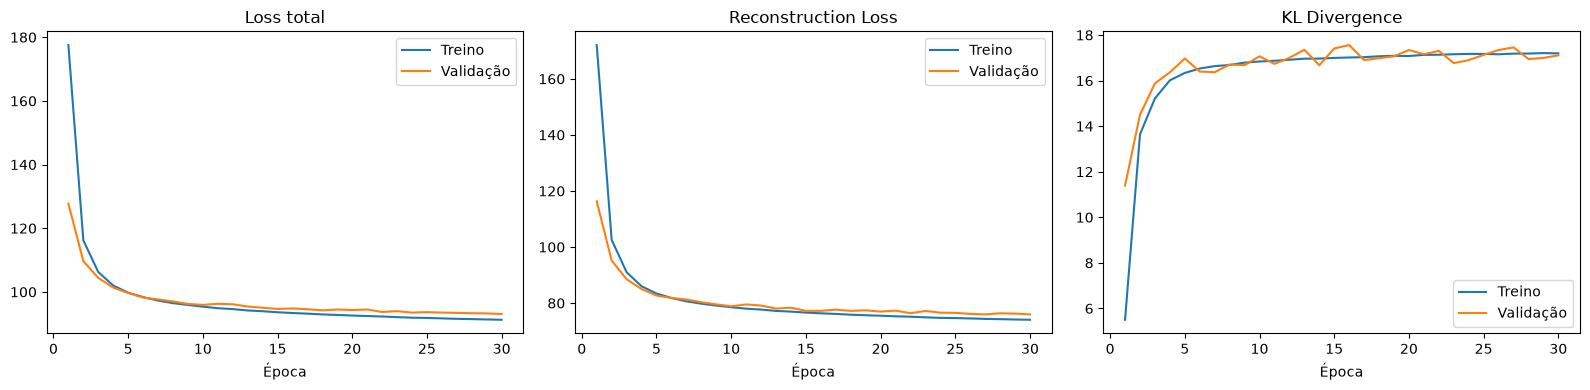

In [13]:
epochs = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss total
axes[0].plot(epochs, history["train_loss"], label="Treino")
axes[0].plot(epochs, history["val_loss"], label="Validação")
axes[0].set_title("Loss total")
axes[0].set_xlabel("Época")
axes[0].legend()

# Reconstrução
axes[1].plot(epochs, history["train_recon"], label="Treino")
axes[1].plot(epochs, history["val_recon"], label="Validação")
axes[1].set_title("Reconstruction Loss")
axes[1].set_xlabel("Época")
axes[1].legend()

# KL
axes[2].plot(epochs, history["train_kl"], label="Treino")
axes[2].plot(epochs, history["val_kl"], label="Validação")
axes[2].set_title("KL Divergence")
axes[2].set_xlabel("Época")
axes[2].legend()

plt.tight_layout()
plt.show()

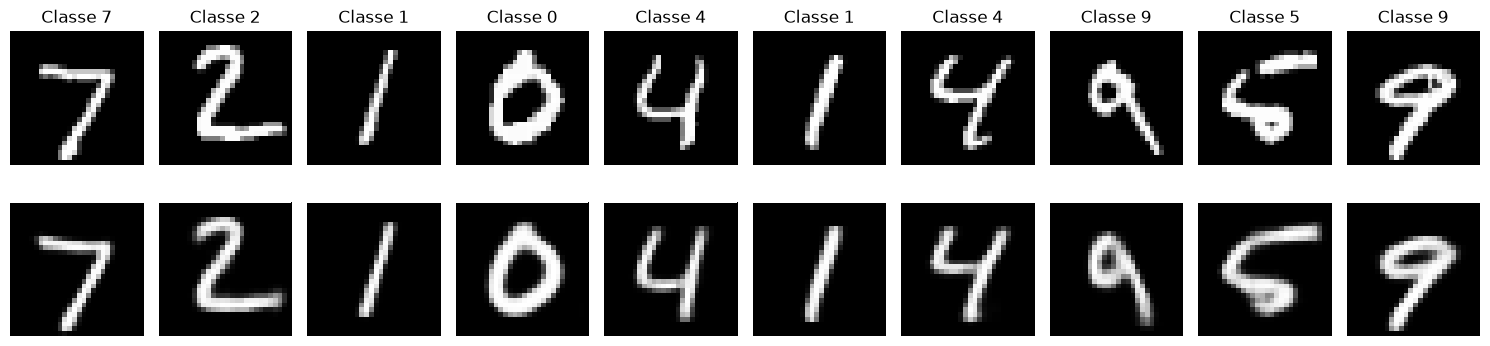

In [14]:
model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

conditions = encode_condition(labels).to(device)

with torch.no_grad():

    mu, logvar = model.encoder(images, conditions)

    # Reconstrução determinística
    reconstruction = model.decoder(mu, conditions)

n = 10

fig, axes = plt.subplots(2, n, figsize=(15, 4))

for i in range(n):

    axes[0, i].imshow(
        images[i].cpu().squeeze(),
        cmap="gray"
    )

    axes[1, i].imshow(
        reconstruction[i].cpu().squeeze(),
        cmap="gray"
    )

    axes[0, i].set_title(f"Classe {labels[i].item()}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstrução")

plt.tight_layout()
plt.show()

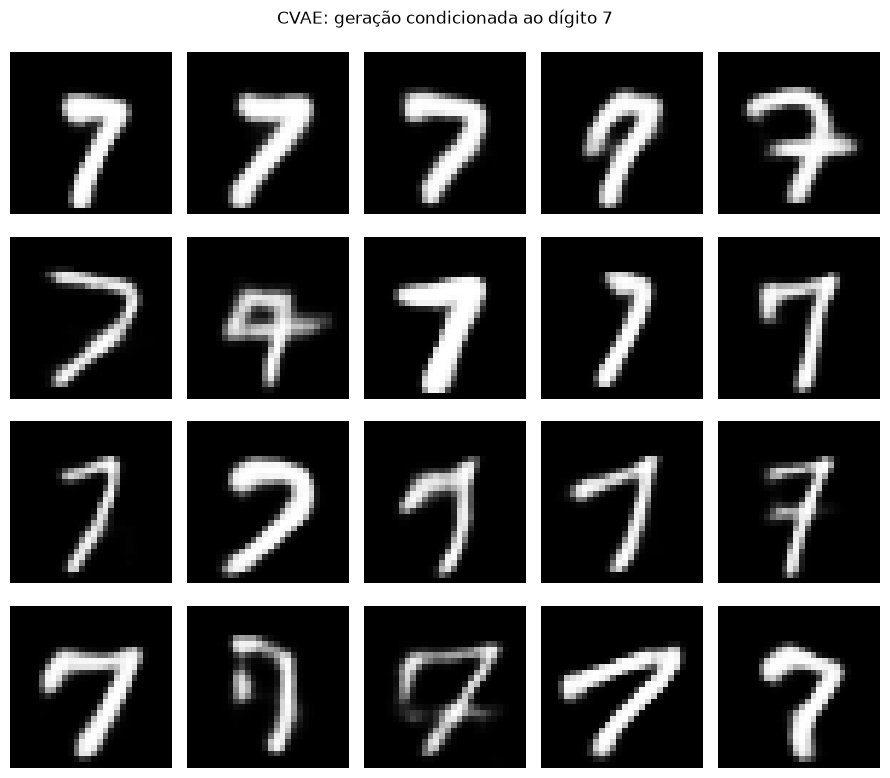

In [15]:
model.eval()

digit = 7
n_samples = 20

# Criar a condição para todas as amostras
labels = torch.full(
    (n_samples,),
    digit,
    dtype=torch.long,
    device=device
)

conditions = encode_condition(labels).to(device)

# Amostrar vetores latentes
z = torch.randn(
    n_samples,
    LATENT_DIM,
    device=device
)

with torch.no_grad():

    generated = model.decoder(z, conditions)

fig, axes = plt.subplots(4, 5, figsize=(9, 8))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated[i].cpu().squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle(f"CVAE: geração condicionada ao dígito {digit}")
plt.tight_layout()
plt.show()

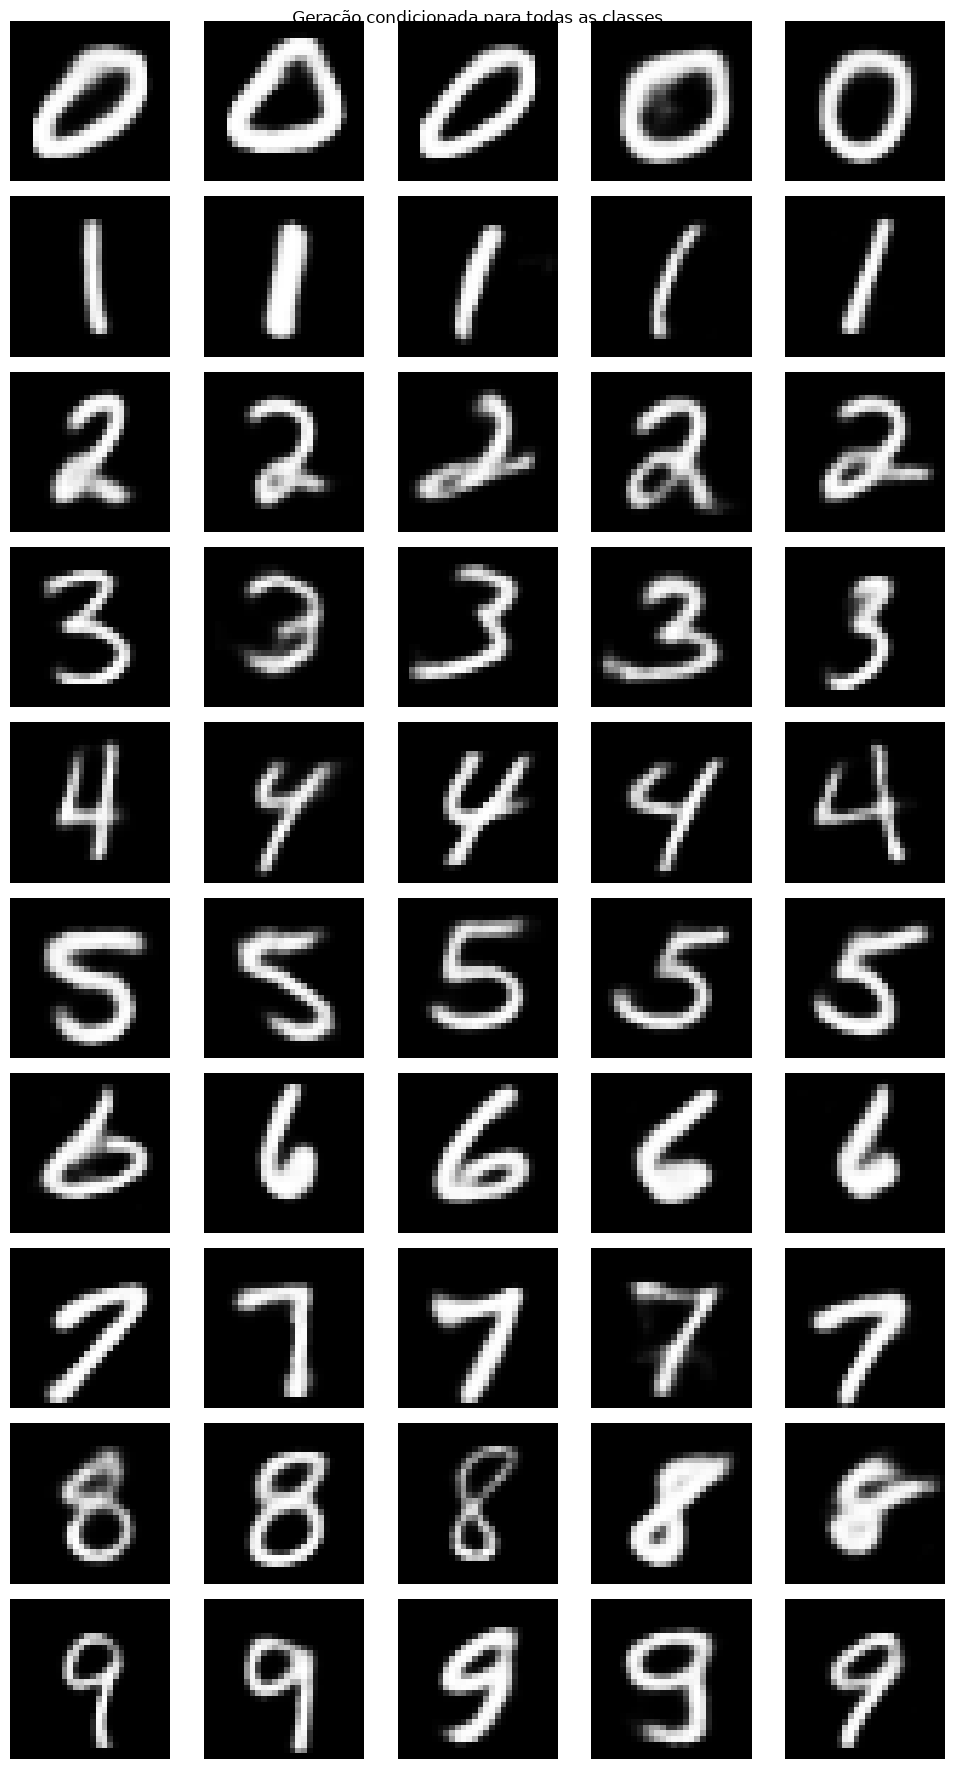

In [16]:
model.eval()

samples_per_class = 5

labels = torch.arange(
    NUM_CLASSES,
    device=device
).repeat_interleave(samples_per_class)

conditions = encode_condition(labels).to(device)

z = torch.randn(
    len(labels),
    LATENT_DIM,
    device=device
)

with torch.no_grad():

    generated = model.decoder(z, conditions)

fig, axes = plt.subplots(
    NUM_CLASSES,
    samples_per_class,
    figsize=(10, 18)
)

for i in range(NUM_CLASSES):

    for j in range(samples_per_class):

        idx = i * samples_per_class + j

        axes[i, j].imshow(
            generated[idx].cpu().squeeze(),
            cmap="gray"
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        f"Dígito {i}",
        fontsize=12
    )

plt.suptitle("Geração condicionada para todas as classes")
plt.tight_layout()
plt.show()

In [17]:
class MNISTClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten()
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)

In [18]:
classifier = MNISTClassifier().to(device)

optimizer_cls = optim.Adam(
    classifier.parameters(),
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()

EPOCHS_CLS = 5

for epoch in range(EPOCHS_CLS):

    classifier.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_cls.zero_grad()

        outputs = classifier(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer_cls.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{EPOCHS_CLS}] "
        f"Loss: {total_loss/len(train_loader):.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.2568 Accuracy: 92.36%
Epoch [2/5] Loss: 0.0653 Accuracy: 97.95%
Epoch [3/5] Loss: 0.0458 Accuracy: 98.58%
Epoch [4/5] Loss: 0.0332 Accuracy: 98.97%
Epoch [5/5] Loss: 0.0279 Accuracy: 99.13%


In [19]:
classifier.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = classifier(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Acurácia na validação: {accuracy:.2f}%")

Acurácia na validação: 98.58%


In [20]:
model.eval()
classifier.eval()

samples_per_class = 100

labels = torch.arange(
    NUM_CLASSES,
    device=device
).repeat_interleave(samples_per_class)

conditions = encode_condition(labels).to(device)

z = torch.randn(
    len(labels),
    LATENT_DIM,
    device=device
)

with torch.no_grad():

    generated = model.decoder(z, conditions)

    outputs = classifier(generated)

    predictions = outputs.argmax(dim=1)

accuracy_cond = (
    predictions == labels
).float().mean().item()

print(
    f"Acurácia condicional: {accuracy_cond * 100:.2f}%"
)

Acurácia condicional: 98.10%


In [21]:
for digit in range(NUM_CLASSES):

    mask = labels == digit

    class_accuracy = (
        predictions[mask] == labels[mask]
    ).float().mean().item()

    print(
        f"Dígito {digit}: "
        f"{class_accuracy * 100:.2f}%"
    )

Dígito 0: 99.00%
Dígito 1: 100.00%
Dígito 2: 97.00%
Dígito 3: 96.00%
Dígito 4: 100.00%
Dígito 5: 98.00%
Dígito 6: 100.00%
Dígito 7: 96.00%
Dígito 8: 97.00%
Dígito 9: 98.00%


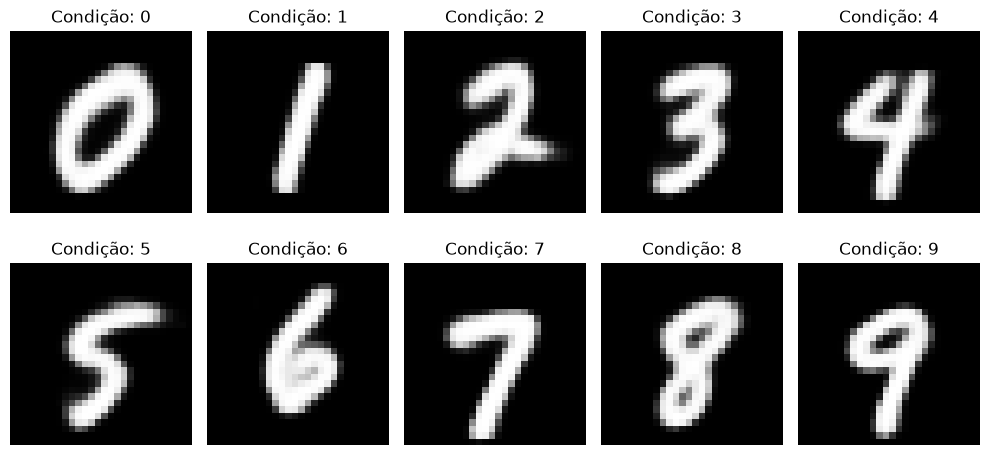

In [22]:
model.eval()

digit_conditions = torch.arange(
    10,
    device=device
)

conditions = encode_condition(digit_conditions)

# Um único vetor latente
z = torch.randn(1, LATENT_DIM, device=device)

# Repetir o mesmo vetor para as dez condições
z = z.repeat(10, 1)

with torch.no_grad():

    generated = model.decoder(z, conditions)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated[i].cpu().squeeze(),
        cmap="gray"
    )

    ax.set_title(f"Condição: {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
model.eval()

all_kl = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        conditions = encode_condition(labels).to(device)

        mu, logvar = model.encoder(images, conditions)

        kl_per_dim = 0.5 * (
            mu.pow(2) +
            logvar.exp() -
            1 -
            logvar
        )

        all_kl.append(kl_per_dim.cpu())

all_kl = torch.cat(all_kl, dim=0)

mean_kl_per_dim = all_kl.mean(dim=0)

for i, value in enumerate(mean_kl_per_dim):

    print(f"Dimensão {i}: KL = {value.item():.6f}")

Dimensão 0: KL = 1.616684
Dimensão 1: KL = 0.889728
Dimensão 2: KL = 0.000201
Dimensão 3: KL = 1.609686
Dimensão 4: KL = 1.479548
Dimensão 5: KL = 2.570033
Dimensão 6: KL = 1.002550
Dimensão 7: KL = 0.000923
Dimensão 8: KL = 1.397453
Dimensão 9: KL = 0.000441
Dimensão 10: KL = 1.510360
Dimensão 11: KL = 0.000228
Dimensão 12: KL = 1.958338
Dimensão 13: KL = 1.062327
Dimensão 14: KL = 1.924866
Dimensão 15: KL = 0.000260
